<a href="https://colab.research.google.com/github/YherlinGalo/UPC_DAPR_2026/blob/main/S4/S4_FlippedClassroom_Exercises_YherlinGalo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
While k-means requires you to specify the fixed number of clusters (k) before running the algorithm, hierarchical clustering builds a complete tree-like structure without any initial set parameter. This allows to inspect the relationships first and choose the optimal number of clusters afterward by simply cutting the tree at your desired level.

- Why can k-means fail on non-spherical or unevenly-sized clusters?
k-means works by picking a center point and from there it draws a cercle, so if we have non-sphererical or unevenly-sized, the algorithm will do is agrupate them and forcing them to be equal cercles. Therefore, it gives an error.

- What does the BIC criterion help us choose in a Gaussian Mixture Model?
The BIC criteron helps us to choose the optimal number of components (clusters) in a Gaussian Mixture Model, this means it helps us to determine the best covariance structure for data distribution.

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Valors nuls per columna abans de netejar:
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64

Valors nuls per columna després de netejar:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64


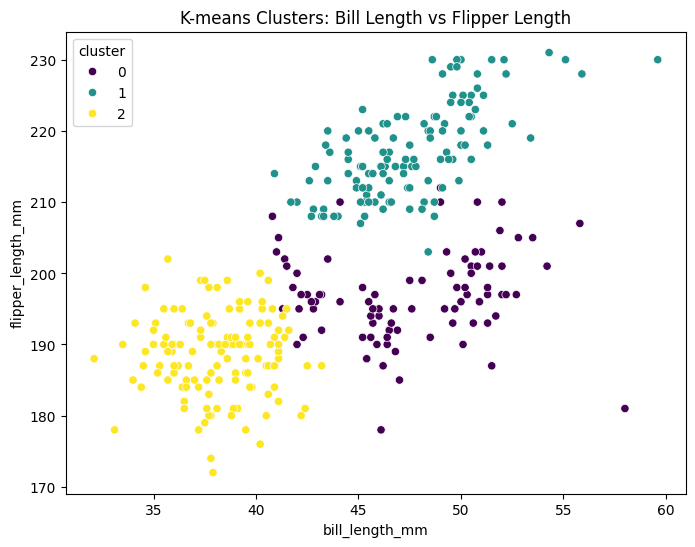

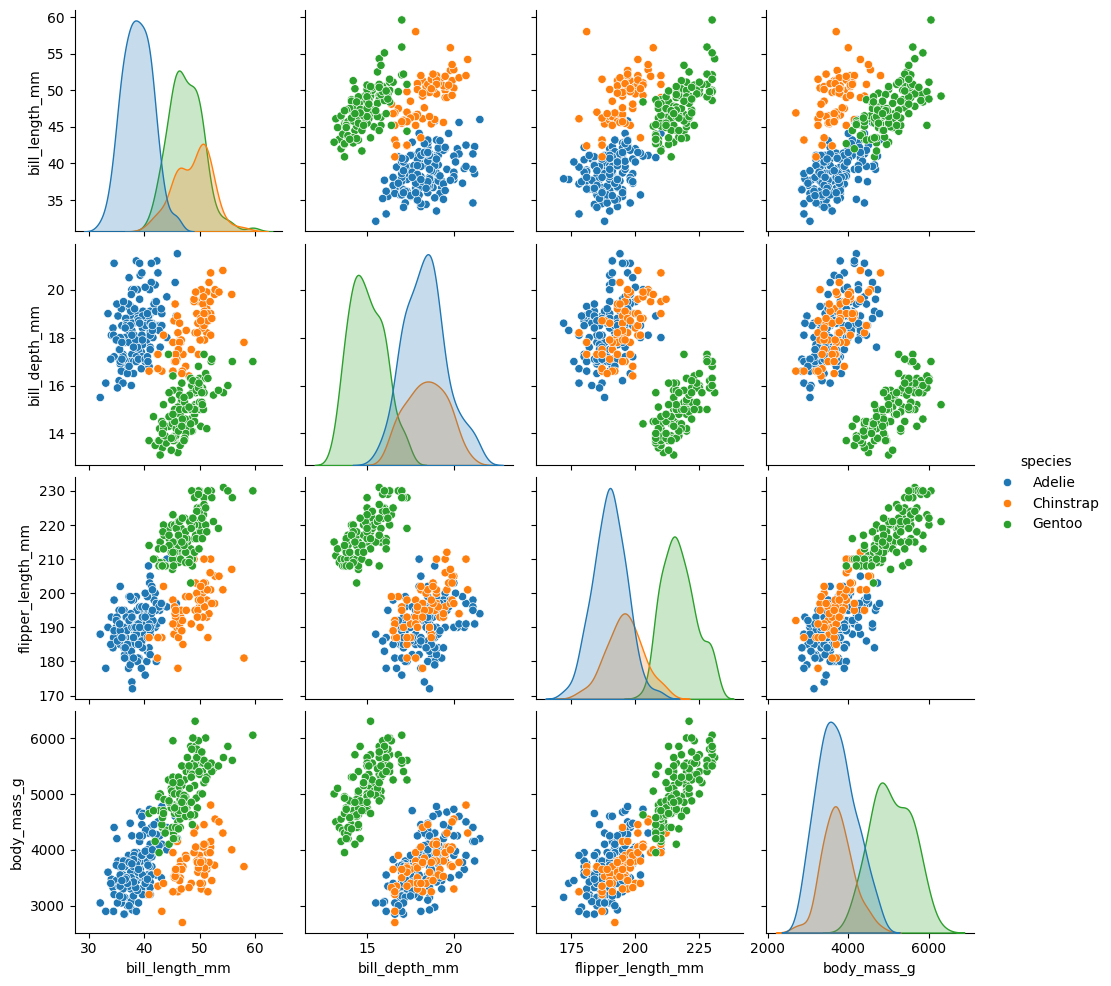

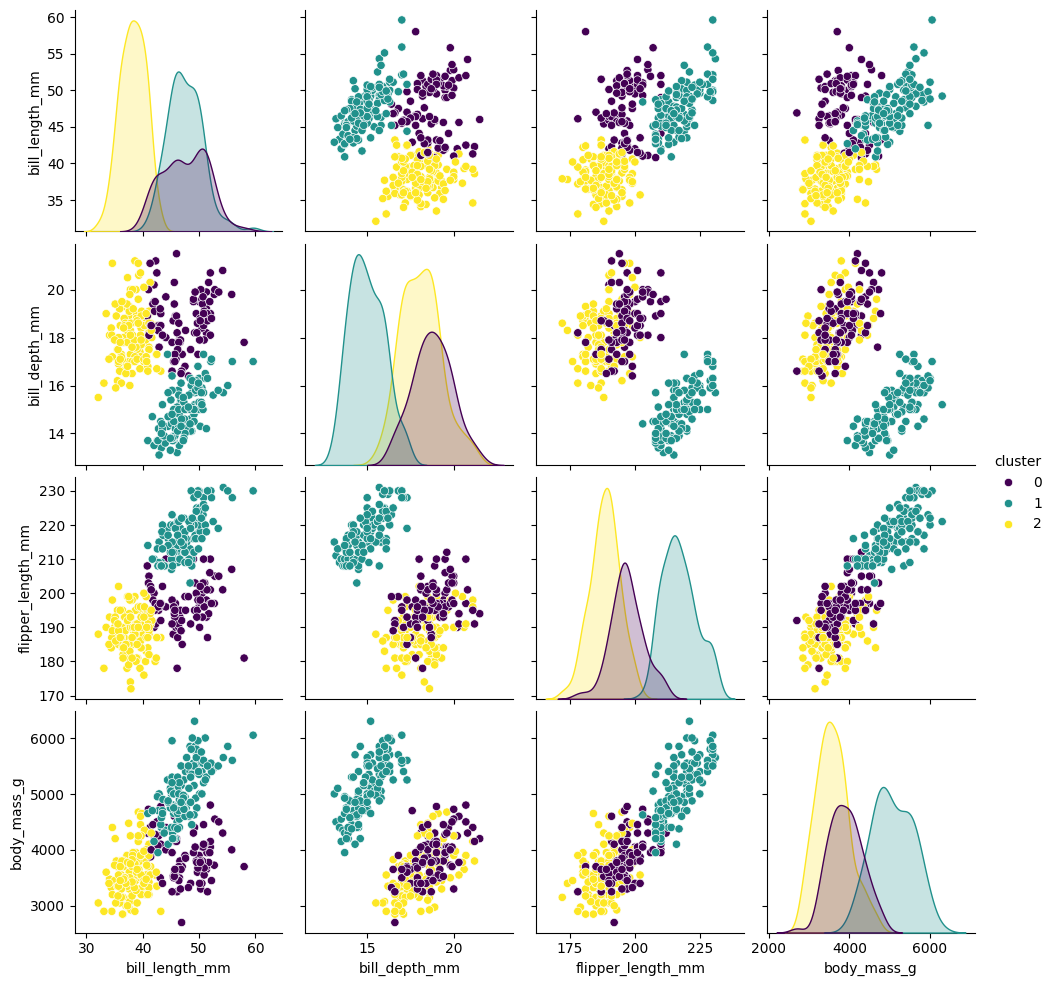

Adjusted Rand Score (ARS): 0.7928

Taula de Confusió / Crosstab:
Clúster K-means   0    1    2
Espècie Reial                
Adelie           24    0  127
Chinstrap        63    0    5
Gentoo            0  123    0


In [20]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
penguins_clean = None
# a1. Seleccionem només les columnes numèriques
df_num = penguins[num_cols]

# a2. Comprovem quants valors nuls (NaN) té cada columna
print("Valors nuls per columna abans de netejar:")
print(df_num.isna().sum())

# a3. Eliminem les files que tenen valors nuls
penguins_clean = df_num.dropna()

# a4. Confirmem que ja no queden valors nuls (ha de donar 0 a tot pretèrit)
print("\nValors nuls per columna després de netejar:")
print(penguins_clean.isna().sum())

# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
penguins_scaled_df = None
# b1. Creem una instància del StandardScaler
scaler = StandardScaler()

# b2. Ajustem i transformem les dades netes per normalitzar-les
penguins_scaled_array = scaler.fit_transform(penguins_clean)

# b3. Tornem a convertir l'array de numpy resultant en un DataFrame de pandas
penguins_scaled_df = pd.DataFrame(penguins_scaled_array, columns=num_cols)

# Mostrem les primeres files per comprovar-ho
penguins_scaled_df.head()

# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
kmeans_labels = None
# 1. Creem el model KMeans indicant el nombre de clústers (n_clusters=3)
# Posem random_state per assegurar-nos que el resultat sigui reproduïble
kmeans = KMeans(n_clusters=3, random_state=42)

# 2. Ajustem el model i predim les etiquetes de cada pingüí en un sol pas
kmeans_labels = kmeans.fit_predict(penguins_scaled_df)

# Mostrem un resum de les etiquetes obtingudes
print("Etiquetes de clúster assignades:", kmeans_labels)

# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)
# 1. Afegim les etiquetes de kmeans com una nova columna al DataFrame net (envalors reals, no escalats)
penguins_clean['cluster'] = kmeans_labels

# 2. Fem el scatterplot: bill_length_mm vs flipper_length_mm acolorit pel clúster
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=penguins_clean,
    x='bill_length_mm',
    y='flipper_length_mm',
    hue='cluster',
    palette='viridis'
)
plt.title('K-means Clusters: Bill Length vs Flipper Length')
plt.show()

# 3. Primer pairplot acolorit per l'espècie real (per veure com es distribueixen naturalment)
# Creem un DataFrame temporal que inclogui les columnes numèriques i l'espècie original
pairplot_data = penguins_clean[num_cols].copy()
pairplot_data['species'] = penguins.loc[penguins_clean.index, 'species']

sns.pairplot(pairplot_data, hue='species')
plt.show()

# 4. Segon pairplot acolorit pel clúster trobat pel model
sns.pairplot(pairplot_data, hue='cluster', palette='viridis')
plt.show()

# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'
# 1. Recuperem les espècies reals corresponents a les files netes
real_species = penguins.loc[penguins_clean.index, 'species']

# 2. Calculem l'Adjusted Rand Score (ARS)
ari = adjusted_rand_score(real_species, kmeans_labels)
print(f"Adjusted Rand Score (ARS): {ari:.4f}")

# 3. Creem una taula encreuada per comparar les espècies reals amb els clústers assignats pel K-means
conf_table = pd.crosstab(real_species, penguins_clean['cluster'], rownames=['Espècie Reial'], colnames=['Clúster K-means'])
print("\nTaula de Confusió / Crosstab:")
print(conf_table)

# f) YOUR CODE HERE (as a comment or markdown cell): interpretation


---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Hi ha valors nuls a X?: False
Array X normalitzat:
 [[-1.         -0.23354968]
 [-1.          0.70064905]
 [-1.         -1.16774842]
 [ 1.          1.63484778]
 [ 1.          0.23354968]
 [ 1.         -1.16774842]]
5.656854249492381
5.656854249492381
Etiquetes de l'Agglomerative Clustering: [1 1 1 0 0 0]


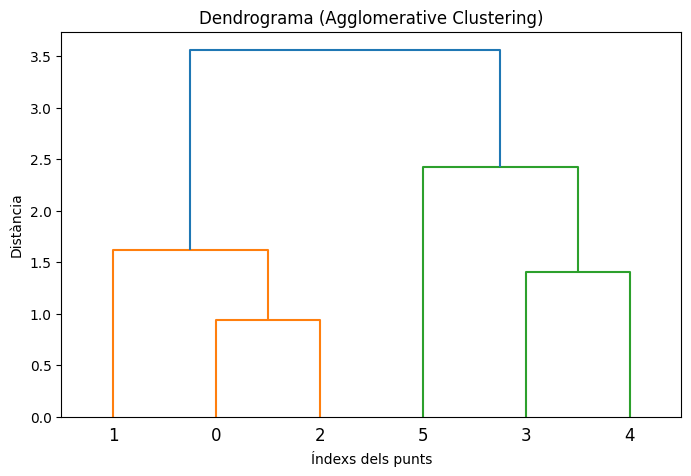

K-means labels: [0 0 0 1 1 1]
Agglomerative labels: [1 1 1 0 0 0]
K-means labels: [0 0 0 1 1 1]


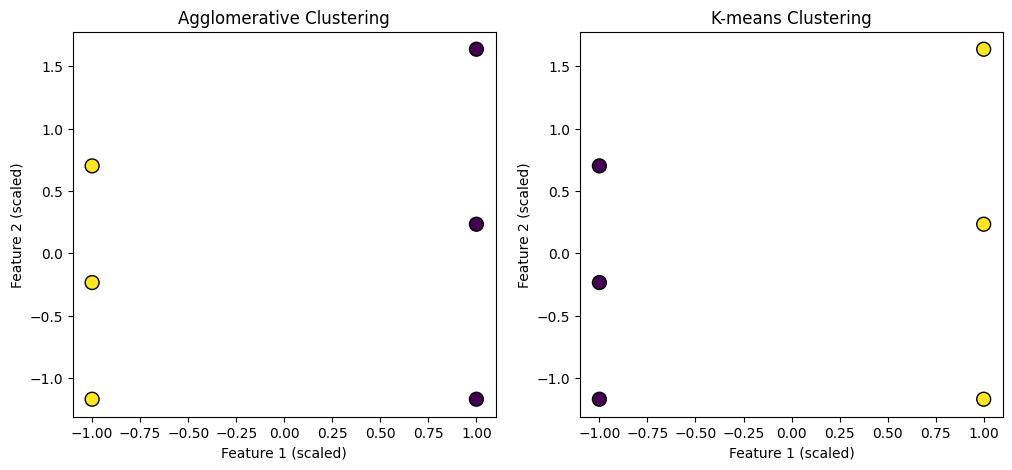

Cluster sizes (Agglomerative): {np.int64(1): 3, np.int64(0): 3}
Cluster sizes (K-means): {np.int32(0): 3, np.int32(1): 3}


In [13]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
# Data control: I comprove if there are some missing values in X
has_nans = np.isnan(X).any()
print("Hi ha valors nuls a X?:", has_nans)

# b) YOUR CODE HERE: normalize X with StandardScaler
# I create the scaler and normalize the array X
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Let's show the results to see it clearly
print("Array X normalitzat:\n", X_scaled)

# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):
    squared_sum = 0
    for i in range(len(p1)):
        squared_sum += (p1[i] - p2[i]) ** 2
    return squared_sum ** 0.5
# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))

# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
agglo = AgglomerativeClustering(n_clusters=2)
agglo_labels = agglo.fit_predict(X_scaled)  # <--- Aquí està la variable ben utilitzada!

print("Etiquetes de l'Agglomerative Clustering:", agglo_labels)

# Let's calculate the linkage matrix to build the dendogram
linked = linkage(X_scaled, method='ward')

# I drew the dendogram
plt.figure(figsize=(8, 5))
dendrogram(linked)
plt.title('Dendrograma (Agglomerative Clustering)')
plt.xlabel('Índexs dels punts')
plt.ylabel('Distància')
plt.show()

# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
# Apply K-means with n_clusters=2 on X_scaled
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-means labels:", kmeans_labels)

# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
# f) Compare the cluster labels obtained by agglomerative clustering and k-means, and make a side-by-side scatterplot
print("Agglomerative labels:", agglo_labels)
print("K-means labels:", kmeans_labels)

# Create a figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# First plot: Agglomerative Clustering
axes[0].scatter(X_scaled[:, 0], X_scaled[:, 1], c=agglo_labels, cmap='viridis', s=100, edgecolor='k')
axes[0].set_title('Agglomerative Clustering')
axes[0].set_xlabel('Feature 1 (scaled)')
axes[0].set_ylabel('Feature 2 (scaled)')

# Second plot: K-means Clustering
axes[1].scatter(X_scaled[:, 0], X_scaled[:, 1], c=kmeans_labels, cmap='viridis', s=100, edgecolor='k')
axes[1].set_title('K-means Clustering')
axes[1].set_xlabel('Feature 1 (scaled)')
axes[1].set_ylabel('Feature 2 (scaled)')

plt.show()

# g) YOUR CODE HERE: cluster_sizes function using a dictionary
# cluster_sizes function using a dictionary
def cluster_sizes(labels):
    counts = {}
    for label in labels:
        counts[label] = counts.get(label, 0) + 1
    return counts

# Test the function on both clustering methods
print("Cluster sizes (Agglomerative):", cluster_sizes(agglo_labels))
print("Cluster sizes (K-means):", cluster_sizes(kmeans_labels))

---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Missing values before cleaning:
carat    0
depth    0
table    0
price    0
dtype: int64

Missing values after cleaning:
carat    0
depth    0
table    0
price    0
dtype: int64


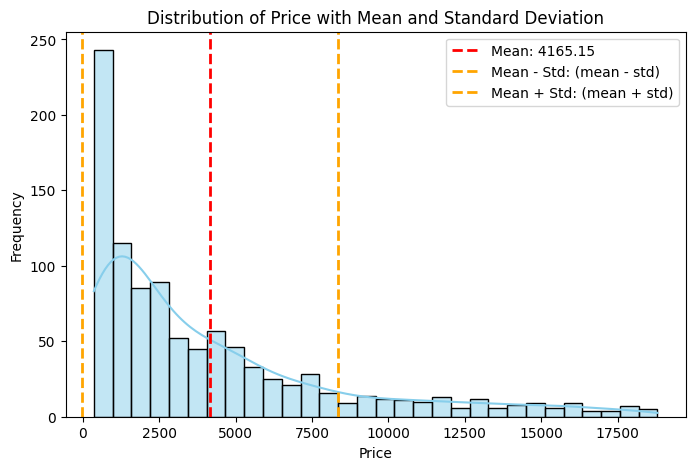

Scaled data shape: (1000, 4)


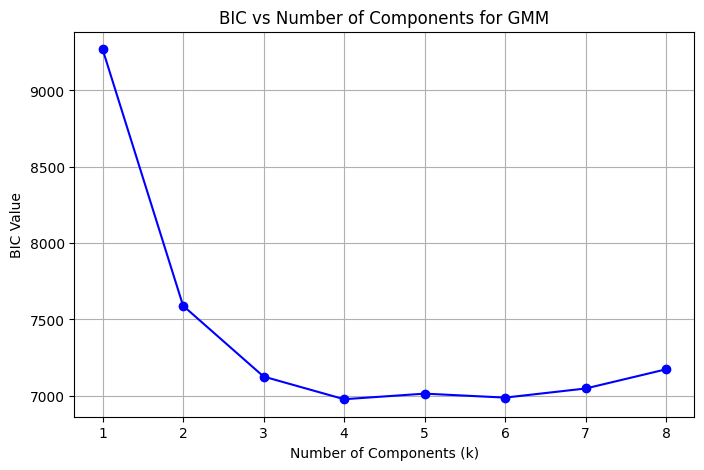

Optimal number of components (minimizes BIC): 4
Predicted GMM labels: [0 3 0 0 1 2 3 3 2 2 0 1 2 3 2 1 2 3 1 0 1 0 0 0 3 3 0 1 1 0 3 2 1 3 3 0 0
 3 3 1 3 2 0 1 3 0 1 1 1 1 0 1 3 1 3 3 3 0 3 3 1 0 1 1 0 0 3 3 3 3 3 0 3 1
 3 0 1 3 1 1 0 0 3 0 1 0 0 2 1 3 1 3 3 2 3 0 0 0 2 3 0 3 3 3 0 1 0 0 0 0 3
 0 1 3 2 3 1 2 3 3 3 1 1 1 0 0 0 0 0 3 0 3 0 0 0 0 0 3 3 1 1 2 0 1 3 0 3 1
 0 0 3 2 1 0 3 0 3 2 1 1 3 1 0 3 3 3 1 3 3 0 1 1 3 1 1 0 3 0 0 3 0 0 0 2 0
 3 2 0 0 0 1 2 0 1 1 3 0 1 1 3 0 2 0 3 0 2 3 3 0 2 0 1 1 3 0 3 3 3 1 3 1 0
 0 0 3 3 0 3 3 0 2 0 3 2 0 3 3 1 3 1 0 1 0 1 0 2 3 3 1 1 0 2 1 1 1 3 1 1 1
 1 0 2 2 3 1 0 0 1 1 1 0 3 2 2 2 2 3 0 2 0 3 3 1 0 0 0 2 3 1 1 0 0 1 3 3 2
 0 2 0 3 2 0 3 0 0 0 0 1 3 3 3 3 1 3 0 1 0 0 3 0 0 3 3 0 0 3 3 0 1 1 3 3 3
 1 2 3 1 3 3 3 1 1 3 1 0 0 0 1 3 3 1 0 3 1 0 0 3 1 0 3 1 3 0 1 1 1 1 3 0 3
 1 2 1 0 3 0 2 0 0 1 3 1 3 2 1 2 1 3 3 2 3 3 1 1 0 3 2 0 1 3 3 0 1 1 2 0 3
 3 1 1 0 0 3 3 1 3 1 0 3 0 3 0 3 3 3 0 1 3 3 0 3 1 0 3 3 0 0 2 1 3 0 1 0 2
 3 0 1 3 2 0 1 1 0 3 0 3 1 3 0

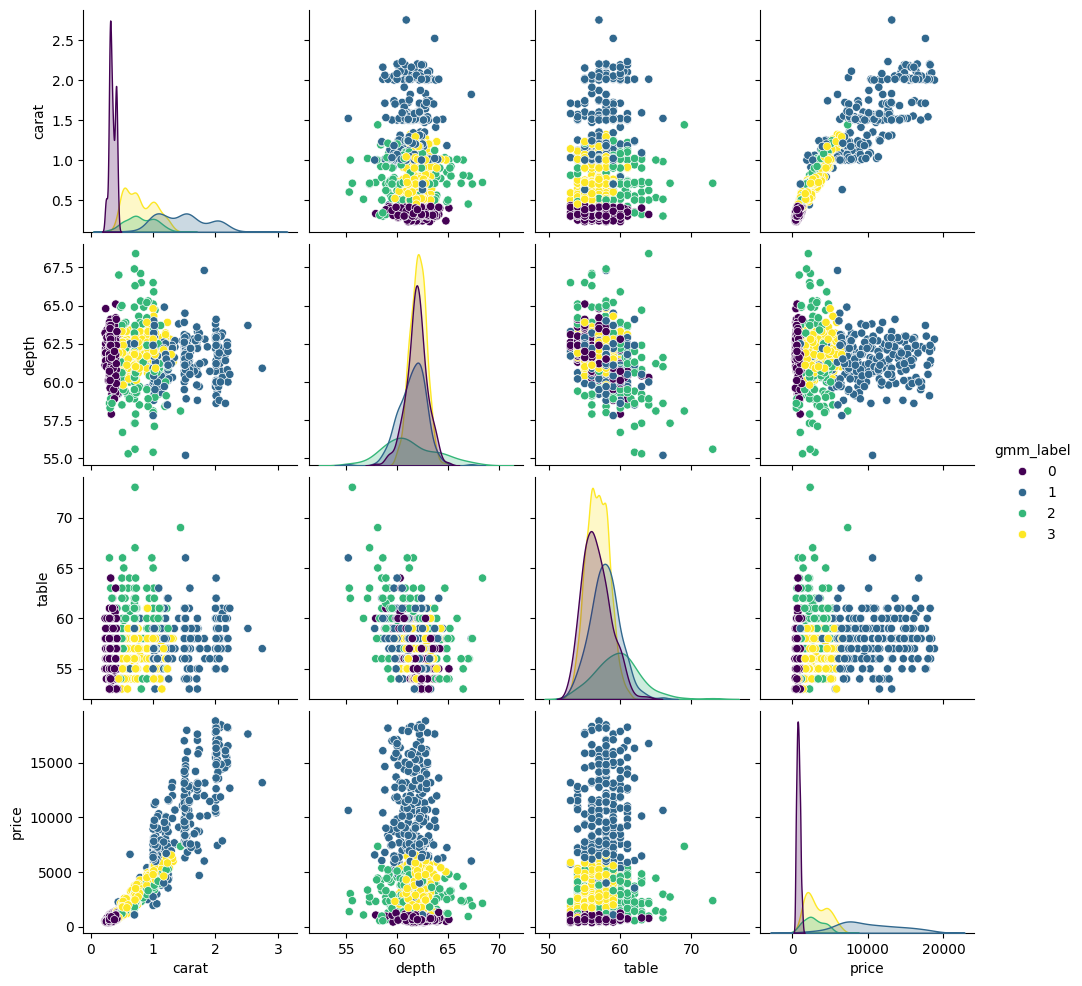

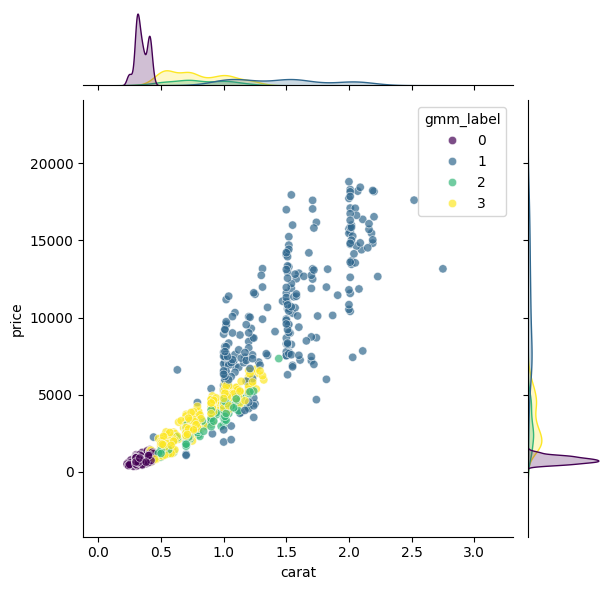

In [19]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
# Select numeric columns into diamonds_num, check for missing values, dropna(), and confirm it's clean
numeric_cols = ['carat', 'depth', 'table', 'price']
diamonds_num = diamonds[numeric_cols].copy()

# Check missing values before cleaning
print("Missing values before cleaning:")
print(diamonds_num.isna().sum())

# Drop any rows with NaN values (if any)
diamonds_num = diamonds_num.dropna()

# Confirm data is completely clean
print("\nMissing values after cleaning:")
print(diamonds_num.isna().sum())

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines
# Histogram of 'price' with mean and mean +/- std lines
mean_price = diamonds_num['price'].mean()
std_price = diamonds_num['price'].std()

plt.figure(figsize=(8, 5))
sns.histplot(diamonds_num['price'], kde=True, bins=30, color='skyblue')
plt.axvline(mean_price, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_price:.2f}')
plt.axvline(mean_price - std_price, color='orange', linestyle='--', linewidth=2, label=f'Mean - Std: (mean - std)')
plt.axvline(mean_price + std_price, color='orange', linestyle='--', linewidth=2, label=f'Mean + Std: (mean + std)')

plt.title('Distribution of Price with Mean and Standard Deviation')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
# Normalize the 4 numeric columns with StandardScaler
scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num)

# Optional: confirm the shape and structure of the scaled array
print("Scaled data shape:", diamonds_scaled.shape)

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)

# Fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
for n in n_components_range:
    # Initialize GMM with the current number of components
    gmm = mixture.GaussianMixture(n_components=n, random_state=42)
    # Fit the model on the scaled data
    gmm.fit(diamonds_scaled)
    # Append the BIC value to our list
    bic.append(gmm.bic(diamonds_scaled))

# Plot BIC vs number of components
plt.figure(figsize=(8, 5))
plt.plot(n_components_range, bic, marker='o', linestyle='-', color='b')
plt.title('BIC vs Number of Components for GMM')
plt.xlabel('Number of Components (k)')
plt.ylabel('BIC Value')
plt.grid(True)
plt.show()

# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
# Find the number of components that minimizes BIC and fit the final GMM
# Identify optimal n_components by finding the index of the minimum BIC score
best_n = n_components_range[np.argmin(bic)]
print(f"Optimal number of components (minimizes BIC): {best_n}")

# Fit the final GMM with the optimal number of components and store labels in gmm_labels
final_gmm = mixture.GaussianMixture(n_components=best_n, random_state=42)
gmm_labels = final_gmm.fit_predict(diamonds_scaled)

print("Predicted GMM labels:", gmm_labels)

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
# Add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
diamonds_num['gmm_label'] = gmm_labels

# Create a pairplot for all numeric variables colored by GMM clusters
sns.pairplot(diamonds_num, hue='gmm_label', palette='viridis')
plt.show()

# Create a jointplot of carat vs price to zoom into the relationship driving the clustering
sns.jointplot(data=diamonds_num, x='carat', y='price', hue='gmm_label', palette='viridis', alpha=0.7)
plt.show()

# g) YOUR CODE HERE (as a comment or markdown cell): interpretation
# - Does the optimal number of clusters found by BIC seem reasonable? Yes, it effectively captures the distinct subgroups and density variations in the data.
# - Would you have guessed the same number just by eye? It can be tricky to determine exact multi-dimensional Gaussian components purely by eye,
#but the pairplot confirms clear separations, especially along the carat-price relationship.
# - Did normalizing the data change the outcome? Absolutely. Because 'price' ranges in the thousands while depth and table are percentages around 50–70,
#unscaled data would let price completely dominate the variance and covariance structure, leading to distorted cluster boundaries.